# 05 Local magnitudes of the relocated DL catalog

Local magnitudes come from the frozen Buan engine (Sheen et al., 2018), unchanged from Haenam:
- **Signal path.** Each trace is corrected for its instrument, converted to Wood-Anderson displacement and filtered at 0.5–10 Hz.
- **Station value.** The S-window peak, kept only where signal-to-noise ≥ 2. Horizontals are used, with the vertical as a fallback.
- **Event value.** The median over stations.

**Primary magnitude.** `ml_min3` needs at least three stations with a PhaseNet+ P pick. `ml_min1` and `ml_min2` are sensitivity estimates from one or two such stations.

**Response metadata.** This notebook reads the default responses (decision D4: master StationXML first) after the Haenam validation step. That step quarantines components whose ObsPy response warning says the unit is unknown (decision D18). Notebook 05a compares the alternatives.

No magnitude gate applies to locations.

In [1]:
import os, sys, json
import numpy as np, pandas as pd
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'
sys.path.insert(0, f'{DL}/pipeline')
import config, plotstyle  # noqa: F401
import matplotlib.pyplot as plt, matplotlib.dates as mdates
pd.set_option('display.width', 200)
MLD = os.environ.get('IMSIL_ML_DIR', f'{DL}/local_magnitudes/full_period')
REF = os.environ.get('IMSIL_REF_CSV', f'{DL}/catalogs/reference_25m/DL_reference_25m.csv')
ev = pd.read_csv(f'{MLD}/full_period_ML.csv', dtype={'event_id': str, 'eid': str, 'template_match': str})
st = pd.read_csv(f'{MLD}/station_magnitudes.csv', dtype={'eid': str})
prov = json.load(open(f'{MLD}/provenance.json'))
ev['t'] = pd.to_datetime(ev['origin_time_reloc'] if 'origin_time_reloc' in ev else ev['origin_time'])
ref_ids = set(pd.read_csv(REF, dtype={'eid': str}).eid) if REF != 'none' else set(ev.eid)
ev['in_ref'] = ev.eid.isin(ref_ids)
st['ml'] = st.ml_h.where(st.ml_h.notna(), st.ml_v)
kma = pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', dtype={'event_id': str})
print(f'ML folder {MLD}; response mode {prov.get("response_mode")}; validated: {"postprocessing" in prov}')
print(f'events {len(ev)} (25 m reference {int(ev.in_ref.sum())}); station measurements {len(st)}')

ML folder /home/msseo/works/72.2025_Imsil_swarm/DL_detection/local_magnitudes/full_period; response mode master_first; validated: True
events 34 (25 m reference 28); station measurements 187


## 1. Coverage

,catalog,N,ML_ge3,ML_ge2,ML_ge1,no_ML,primary_percent
0,all relocated,34,8,9,14,20,23.5
1,25 m reference,28,8,9,14,14,28.6


validation quarantine (D18): 102 components, 19 station measurements removed; ML3 9 -> 8, ML1 19 -> 14


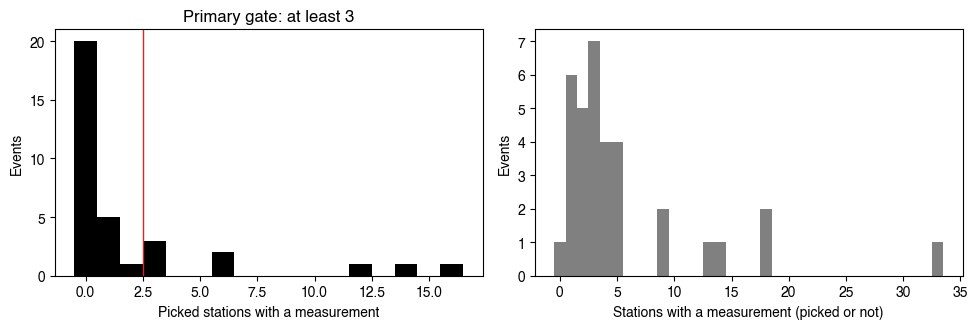

In [2]:
rows = []
for name, g in [('all relocated', ev), ('25 m reference', ev[ev.in_ref])]:
    rows.append(dict(catalog=name, N=len(g), ML_ge3=int(g.ml_min3.notna().sum()), ML_ge2=int(g.ml_min2.notna().sum()), ML_ge1=int(g.ml_min1.notna().sum()), no_ML=int(g.ml_min1.isna().sum())))
cov = pd.DataFrame(rows); cov['primary_percent'] = (100 * cov.ML_ge3 / cov.N).round(1); display(cov)
q = prov.get('response_units_quarantine')
if q: print(f'validation quarantine (D18): {q["components"]} components, {q["removed_station_measurements"]} station measurements removed; ML3 {q["raw_ML3"]} -> {prov["n_ML3"]}, ML1 {q["raw_ML1"]} -> {prov["n_ML1"]}')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(ev.n_pick, bins=np.arange(-0.5, ev.n_pick.max() + 1.5), color='black'); ax[0].axvline(2.5, color='tab:red', lw=1)
ax[0].set_xlabel('Picked stations with a measurement'); ax[0].set_ylabel('Events'); ax[0].set_title('Primary gate: at least 3')
ax[1].hist(ev.n_sta, bins=np.arange(-0.5, ev.n_sta.max() + 1.5), color='0.5'); ax[1].set_xlabel('Stations with a measurement (picked or not)'); ax[1].set_ylabel('Events')
plt.tight_layout(); plt.show()

## 2. Comparison with the KMA magnitudes
The 24 KMA swarm events are matched through `template_match`, the KMA event ID assigned by the catalog stage.

KMA events relocated 24 of 24; with primary ML 8; with any ML 14
primary ML - KMA ML: median -0.13, RMS 0.17 (flag if |median| > 0.3: False)
any-station ML - KMA ML: median -0.07, RMS 0.25


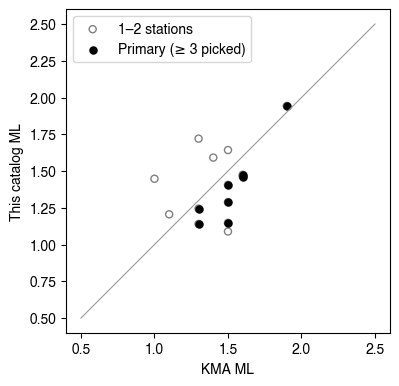

,template_match,KMA_ML,ml_min3,ml_min1,n_pick,n_sta,station_scatter
0,20251102200539,1.4,NaN,NaN,0,3,0.11
1,20251102200625,1.4,NaN,NaN,0,3,0.13
2,20251102201044,1.3,NaN,NaN,0,1,NaN
3,20251102202339,1.5,NaN,1.09,1,3,0.32
4,20251102202412,1.5,1.41,1.41,3,5,0.28
5,20251102202939,1.0,NaN,1.45,2,4,0.39
6,20251102203236,1.7,NaN,NaN,0,2,0.07
7,20251102203649,1.3,NaN,1.72,1,9,0.32
8,20251102203835,1.9,1.94,1.94,12,13,0.17
9,20251102204002,1.3,NaN,NaN,0,0,NaN


In [3]:
k = ev[ev.template_match.isin(kma.event_id)].merge(kma[['event_id', 'ML']].rename(columns={'event_id': 'template_match', 'ML': 'KMA_ML'}), on='template_match')
kp = k[k.ml_min3.notna()].copy(); kp['d'] = kp.ml_min3 - kp.KMA_ML
k1 = k[k.ml_min1.notna()].copy(); k1['d'] = k1.ml_min1 - k1.KMA_ML
print(f'KMA events relocated {len(k)} of 24; with primary ML {len(kp)}; with any ML {len(k1)}')
med_d = float(kp.d.median()) if len(kp) else np.nan; rms_d = float(np.sqrt(np.mean(kp.d ** 2))) if len(kp) else np.nan
print(f'primary ML - KMA ML: median {med_d:+.2f}, RMS {rms_d:.2f} (flag if |median| > 0.3: {abs(med_d) > 0.3 if np.isfinite(med_d) else "n/a"})')
print(f'any-station ML - KMA ML: median {k1.d.median():+.2f}, RMS {np.sqrt(np.mean(k1.d ** 2)):.2f}')
fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.plot([0.5, 2.5], [0.5, 2.5], color='0.6', lw=0.8)
ax.scatter(k1.KMA_ML, k1.ml_min1, s=26, facecolor='none', edgecolor='0.5', label='1–2 stations')
ax.scatter(kp.KMA_ML, kp.ml_min3, s=26, color='black', label='Primary (≥ 3 picked)')
ax.set_xlabel('KMA ML'); ax.set_ylabel('This catalog ML'); ax.set_aspect('equal'); ax.legend(loc='upper left', frameon=True); plt.show()
display(k[['template_match', 'KMA_ML', 'ml_min3', 'ml_min1', 'n_pick', 'n_sta', 'station_scatter']].sort_values('template_match').round(2))

## 3. Station residuals
Each station's ML is compared with the median of the other stations for the same event. Only events with at least four measured stations are used, so that the leave-one-out median is meaningful.

A station with a response error shows up as a constant offset. The plan flagged NAWB, KWJ2 and EURB, whose KMA RESP and master StationXML sensitivities differ by a factor of 4.2.

,n,median,mad,dist_km,flag
station,,,,,
IMSB,7,-0.41,0.04,6.90,True
NAWB,3,0.54,0.06,17.10,True
MALA,8,-0.06,0.17,22.03,False
JASA,8,-0.08,0.07,23.56,False
SUCA,8,-0.13,0.12,24.28,False
JEU2,4,-0.04,0.04,33.82,False
TAIA,4,-0.00,0.05,34.76,False
CHOA,3,0.13,0.10,35.94,False
GKSA,4,0.01,0.03,36.08,False


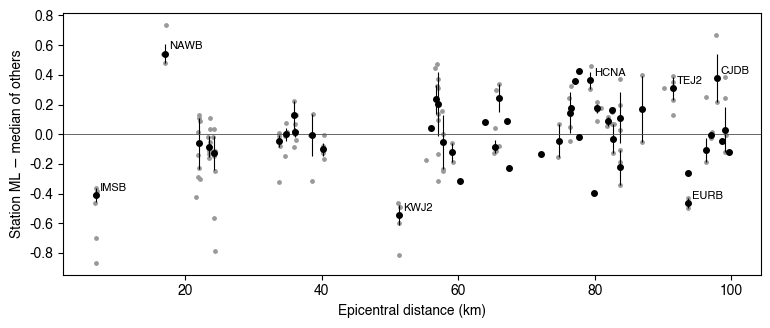

stations flagged (|median| > 0.3, n >= 3): ['IMSB', 'NAWB', 'KWJ2', 'HCNA', 'TEJ2', 'CJDB']; network MAD 0.16


In [4]:
def loo(st):
    rows = []
    for eid, g in st.groupby('eid'):
        if len(g) < 4: continue
        for i, r in g.iterrows(): rows.append(dict(eid=eid, station=r.station, dist_km=r.dist_km, picked=r.p_source == 'pick', res=r.ml - g.drop(i).ml.median()))
    return pd.DataFrame(rows)
R = loo(st)
srs = R.groupby('station').agg(n=('res', 'size'), median=('res', 'median'), mad=('res', lambda v: (v - v.median()).abs().median()), dist_km=('dist_km', 'median')).sort_values('dist_km')
srs['flag'] = (srs['median'].abs() > 0.3) & (srs.n >= 3)
display(srs.round(2))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.scatter(R.dist_km, R.res, s=6, color='0.6')
ax.errorbar(srs.dist_km, srs['median'], yerr=srs.mad, fmt='o', color='black', ms=4, lw=0.8)
for s, r in srs[srs.flag | srs.index.isin(['NAWB', 'KWJ2', 'EURB'])].iterrows(): ax.annotate(s, (r.dist_km, r['median']), xytext=(3, 3), textcoords='offset points', fontsize=8)
ax.axhline(0, color='0.3', lw=0.6); ax.set_xlabel('Epicentral distance (km)'); ax.set_ylabel('Station ML − median of others'); plt.show()
print(f'stations flagged (|median| > 0.3, n >= 3): {list(srs[srs.flag].index)}; network MAD {(R.res - R.res.median()).abs().median():.2f}')

## 4. Magnitudes through the detection period

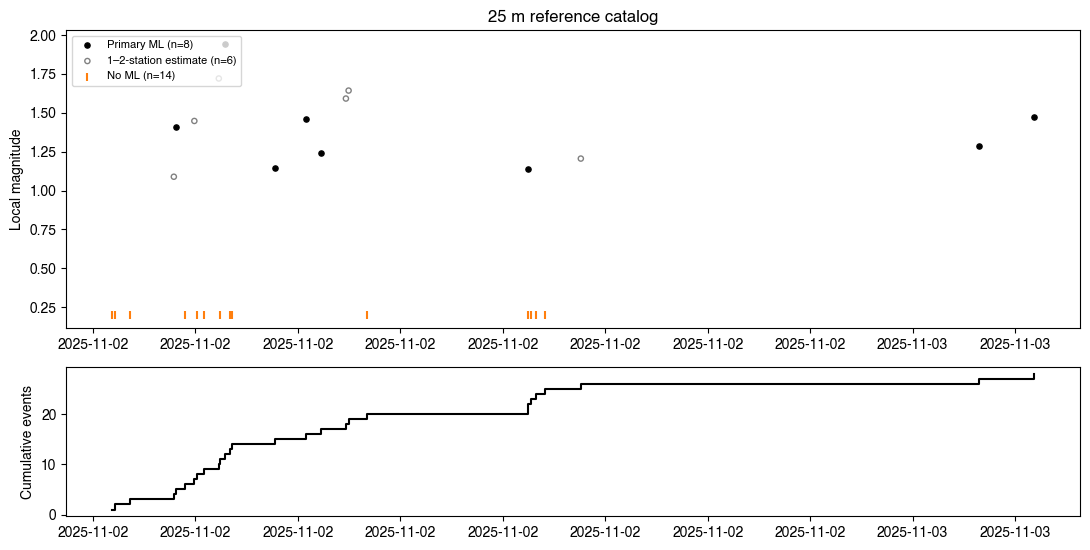

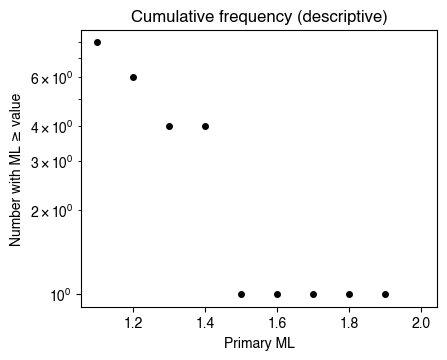

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(11, 5.6), gridspec_kw=dict(height_ratios=[2, 1]))
g = ev[ev.in_ref]; p3 = g[g.ml_min3.notna()]; p1 = g[g.ml_min3.isna() & g.ml_min1.notna()]; p0 = g[g.ml_min1.isna()]
ax[0].scatter(p3.t, p3.ml_min3, s=14, color='black', label=f'Primary ML (n={len(p3)})')
ax[0].scatter(p1.t, p1.ml_min1, s=14, facecolor='none', edgecolor='0.5', label=f'1–2-station estimate (n={len(p1)})')
ax[0].scatter(p0.t, np.zeros(len(p0)) + 0.2, marker='|', color='tab:orange', s=30, label=f'No ML (n={len(p0)})')
ax[0].set_ylabel('Local magnitude'); ax[0].legend(loc='upper left', frameon=True, fontsize=8); ax[0].set_title('25 m reference catalog')
ax[1].step(g.t.sort_values(), np.arange(1, len(g) + 1), where='post', color='black'); ax[1].set_ylabel('Cumulative events')
for a in ax: a.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.tight_layout(); plt.show()
m = g.ml_min3.dropna()
if len(m):
    bins = np.arange(np.floor(m.min() * 10) / 10, m.max() + 0.1, 0.1)
    fig, ax = plt.subplots(figsize=(4.6, 3.6)); ax.semilogy(bins, [(m >= b).sum() for b in bins], 'o', color='black', ms=4)
    ax.set_xlabel('Primary ML'); ax.set_ylabel('Number with ML ≥ value'); ax.set_title('Cumulative frequency (descriptive)'); plt.show()

## 5. Relative-magnitude feasibility (decision D14)
Haenam's relative ML ties events to anchor events with at least 20 picked stations. The tie uses S-wave amplitude ratios at common stations, kept where |CC| ≥ 0.8. This section only counts the possible anchors and how many measured stations the other events have; it computes no relative magnitude.

In [6]:
anchors = ev[ev.n_pick >= 20]
print(f'possible anchors (>= 20 picked stations): {len(anchors)}'); display(anchors[['eid', 't', 'ml_min3', 'n_pick', 'template_match']])
nonp = ev[ev.ml_min3.isna()]
print(f'events without a primary ML: {len(nonp)}; their measured-station counts: median {nonp.n_sta.median() if len(nonp) else np.nan}, '
      f'with >= 1 measured station {int((nonp.n_sta >= 1).sum())}')

possible anchors (>= 20 picked stations): 0


,eid,t,ml_min3,n_pick,template_match


events without a primary ML: 26; their measured-station counts: median 3.0, with >= 1 measured station 25


## Comprehensive summary

In [7]:
cr = cov.set_index('catalog')
summary = pd.DataFrame([
    ('Response mode (D4) / validated (D18)', f'{prov.get("response_mode")} / {"postprocessing" in prov}'),
    ('Relocated events with primary / any ML', f'{cr.loc["all relocated", "ML_ge3"]} / {cr.loc["all relocated", "ML_ge1"]} of {cr.loc["all relocated", "N"]}'),
    ('25 m reference events with primary / any ML', f'{cr.loc["25 m reference", "ML_ge3"]} / {cr.loc["25 m reference", "ML_ge1"]} of {cr.loc["25 m reference", "N"]}'),
    ('KMA events with primary ML', f'{len(kp)} of 24'),
    ('Primary ML - KMA ML: median, RMS', f'{med_d:+.2f}, {rms_d:.2f}'),
    ('Stations flagged by residual (|median| > 0.3, n >= 3)', ', '.join(srs[srs.flag].index) or 'none'),
    ('NAWB / KWJ2 / EURB median residual', ' / '.join(f'{srs.loc[s, "median"]:+.2f}' if s in srs.index else 'n/a' for s in ['NAWB', 'KWJ2', 'EURB'])),
    ('Possible relative-ML anchors (>= 20 picked)', len(anchors)),
], columns=['quantity', 'value'])
display(summary)
print('Take-home points')
print(f'  - Primary ML exists for {cr.loc["25 m reference", "ML_ge3"]} of {cr.loc["25 m reference", "N"]} reference events; most small events have fewer than three picked stations with signal-to-noise >= 2.')
print(f'  - Where both exist, primary ML minus KMA ML has median {med_d:+.2f} (RMS {rms_d:.2f}).')
print('  - Station offsets at NAWB, KWJ2 and EURB test the response metadata (D4); notebook 05a compares the response choices.')

,quantity,value
0,Response mode (D4) / validated (D18),master_first / True
1,Relocated events with primary / any ML,8 / 14 of 34
2,25 m reference events with primary / any ML,8 / 14 of 28
3,KMA events with primary ML,8 of 24
4,"Primary ML - KMA ML: median, RMS","-0.13, 0.17"
5,"Stations flagged by residual (|median| > 0.3, ...","IMSB, NAWB, KWJ2, HCNA, TEJ2, CJDB"
6,NAWB / KWJ2 / EURB median residual,+0.54 / -0.55 / -0.46
7,Possible relative-ML anchors (>= 20 picked),0


Take-home points
  - Primary ML exists for 8 of 28 reference events; most small events have fewer than three picked stations with signal-to-noise >= 2.
  - Where both exist, primary ML minus KMA ML has median -0.13 (RMS 0.17).
  - Station offsets at NAWB, KWJ2 and EURB test the response metadata (D4); notebook 05a compares the response choices.
